In [1]:
import matplotlib.pyplot as plt
import numpy as np
import re

import sklearn

import multiphase_flow_utils
from multiphase_flow_utils import read_and_split_file

In [2]:
sklearn.set_config(transform_output='pandas')
files = [
    'combined_process.xlsx',
]
dataset_nums = ['Process']
ydata_col = 'Erro ([%])'

products = True
triples = False

In [3]:
def units_and_description(df):
    split_names = [
        re.split(r'[()]',x) for x in df.columns.values.tolist()
    ]
    
    unit = []
    desc = []
    for split in split_names:
        desc += [split[0]]
        if len(split) > 2:
            unit += [split[1]]

        else:
            unit += ['no unit']
    return unit,desc

In [4]:
nplots = len(files)
subplots_args = (nplots,2)
subplot_kw = dict(
    figsize=(8,1.5*nplots+2.6),
    sharex='col',
    squeeze=False,
)

Erro ([%])
True
True
(831, 26)


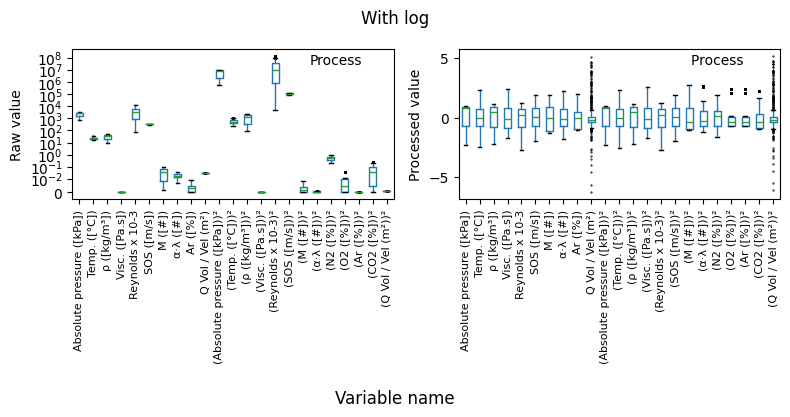

In [5]:
fig,axs = plt.subplots(
    *subplots_args,**subplot_kw
)

def logabs(x):
    return np.log1p(np.abs(x))

scal = sklearn.pipeline.Pipeline(
    steps=[
        ('log',sklearn.preprocessing.FunctionTransformer(logabs)),
        ('scaling',sklearn.preprocessing.StandardScaler(),)
    ]
)

for num,(file,ax_row,ds) in enumerate(zip(files,axs,dataset_nums)):
    all_x,all_y = read_and_split_file(
        file,ydata_col,products=products
    )
    
    print(all_x.shape)
    
    ax_row[0].set_ylabel('Raw value')
    ax_row[1].set_ylabel('Processed value')
    
    unit,description = units_and_description(all_x)
    mean_cols_mask = np.array([x.split('_')[0]=='media' for x in description])
    not_a_cols_mask = np.array([re.search(r'[BCD2]', x[-3:]) is not None for x in description])
    
    mean_cols_mask = np.ones_like(mean_cols_mask,dtype=bool)
    mean_x = all_x.drop(
        columns=all_x.columns.values[
            np.logical_or(~mean_cols_mask,not_a_cols_mask)
        ]
    )
    #print(all_x)
    #print(mean_x)
    
    #ax_row[0].set_title('Unscaled')
    ax_row[0].text(
        0.9,0.9,'{}'.format(ds),
        ha='right',
        transform=ax_row[0].transAxes
    )
    #all_x.boxplot(
    mean_x.boxplot(
        ax=ax_row[0],
        rot=90,
        grid=False,flierprops=dict(
            marker='.',color='0.2',markersize=1
        ),#orientation='horizontal'
    )
    ax_row[0].set_yscale('symlog',linthresh=0.01)
    
    #plt.xticks(fontsize=8)
    
    #ax_row[1].set_title('Scaled')
    ax_row[1].text(
        0.9,0.9,'{} '.format(ds),
        ha='right',
        transform=ax_row[1].transAxes
    )
    #scal.fit_transform(all_x).boxplot(
    scal.fit_transform(mean_x).boxplot(
        ax=ax_row[1],
        rot=90,
        grid=False,flierprops=dict(
            marker='.',color='0.2',markersize=1
        ),#orientation='horizontal'
    )
    
    #plt.xticks(fontsize=8)
labels = [x for x in mean_x.columns.values]

axs[-1,0].set_xticklabels(1*labels)
axs[-1,1].set_xticklabels(1*labels)

t=axs[-1,0].tick_params(axis='x',labelsize=8)
t=axs[-1,1].tick_params(axis='x',labelsize=8)

fig.suptitle('With log')
fig.supxlabel('Variable name')

# t=axs[0,1].tick_params(
#     np.arange(len(all_x.T)),
#     labels=[]
# )

fig.tight_layout()

In [6]:
mean_x.columns.values

<StringArray>
[   'Absolute pressure ([kPa])',                 'Temp. ([°C])',
                  'ρ ([kg/m³])',               'Visc. ([Pa.s])',
              'Reynolds x 10-3',                  'SOS ([m/s])',
                      'M ([#])',                    'α·λ ([#])',
                     'Ar ([%])',             'Q Vol / Vel (m²)',
 '(Absolute pressure ([kPa]))²',              '(Temp. ([°C]))²',
               '(ρ ([kg/m³]))²',            '(Visc. ([Pa.s]))²',
           '(Reynolds x 10-3)²',               '(SOS ([m/s]))²',
                   '(M ([#]))²',                 '(α·λ ([#]))²',
                  '(N2 ([%]))²',                  '(O2 ([%]))²',
                  '(Ar ([%]))²',                 '(CO2 ([%]))²',
          '(Q Vol / Vel (m²))²']
Length: 23, dtype: str

Erro ([%])
True
True
(831, 26)


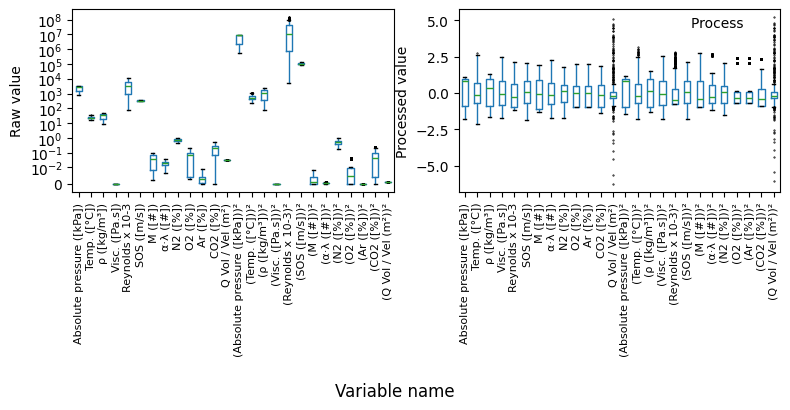

In [8]:
fig,axs = plt.subplots(
    *subplots_args,**subplot_kw
)

def logabs(x):
    return np.log1p(np.abs(x))

scal = sklearn.pipeline.Pipeline(
    steps=[
        #('log',sklearn.preprocessing.FunctionTransformer(logabs)),
        ('scaling',sklearn.preprocessing.StandardScaler(),)
    ]
)

for num,(file,ax_row,ds) in enumerate(zip(files,axs,dataset_nums)):
    all_x,all_y = read_and_split_file(
        file,ydata_col,products=products
    )
    
    print(all_x.shape)
    
    ax_row[0].set_ylabel('Raw value')
    ax_row[1].set_ylabel('Processed value')
    
    unit,description = units_and_description(all_x)
    mean_cols_mask = np.array([x.split('_')[0]=='media' for x in description])
    not_a_cols_mask = np.array([re.search(r'[BCD2]', x[-3:]) is not None for x in description])
    
    mean_cols_mask = np.ones_like(mean_cols_mask,dtype=bool)
    not_a_cols_mask = ~mean_cols_mask
    mean_x = all_x.drop(
        columns=all_x.columns.values[
            np.logical_or(~mean_cols_mask,not_a_cols_mask)
        ]
    )
    #print(all_x)
    #print(mean_x)
    
    #ax_row[0].set_title('Unscaled')
#     ax_row[0].text(
#         0.9,0.9,'{}'.format(ds),
#         ha='right',
#         transform=ax_row[0].transAxes
#     )
    #all_x.boxplot(
    mean_x.boxplot(
        ax=ax_row[0],
        rot=90,
        grid=False,flierprops=dict(
            marker='.',color='0.2',markersize=1
        ),#orientation='horizontal'
    )
    ax_row[0].set_yscale('symlog',linthresh=0.01)
    
    #plt.xticks(fontsize=8)
    
    #ax_row[1].set_title('Scaled')
    ax_row[1].text(
        0.9,0.9,'{} '.format(ds),
        ha='right',
        transform=ax_row[1].transAxes
    )
    #scal.fit_transform(all_x).boxplot(
    scal.fit_transform(mean_x).boxplot(
        ax=ax_row[1],
        rot=90,
        grid=False,flierprops=dict(
            marker='.',color='0.2',markersize=1
        ),#orientation='horizontal'
    )
    
    #plt.xticks(fontsize=8)
labels = [x for x in mean_x.columns.values]

axs[-1,0].set_xticklabels(1*labels)
axs[-1,1].set_xticklabels(1*labels)

t=axs[-1,0].tick_params(axis='x',labelsize=8)
t=axs[-1,1].tick_params(axis='x',labelsize=8)

#fig.suptitle('With log')
fig.supxlabel('Variable name')

# t=axs[0,1].tick_params(
#     np.arange(len(all_x.T)),
#     labels=[]
# )

fig.tight_layout()